In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats

In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_TypeScript_model_dataset2_TypeScript_similarities.csv"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq2_TypeScript/RESULTS/results_evaluate_dataset2_TypeScript_combination_rq2_TypeScript_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_TypeScript_complete.json" 
DATASET2_TESTING = f"{DATA_PATH}/dataset2_TypeScript_testing.json"
DATASET2_METADATA = f"{DATA_PATH}/dataset2_TypeScript_metadata.json"

## Dataset2

In [3]:
df_complete = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test = pd.read_json(DATASET2_TESTING)
df_test

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,"v27 = {\n ""kind"": ""LinkedField"",\n ""alias"": ...","v27 = {\n ""kind"": ""LinkedField"",\n ""alias"": ...",\nv18 = [\n,v19 = [\n,34487,7
1,"""scroll-padding-bottom""?: ScrollPaddingBotto...","""scroll-padding-bottom""?: Property.ScrollPad...","\n ""scroll-padding-bottom""?: ScrollPaddingBot...","""scroll-padding-bottom""?: Property.ScrollPad...",50552,32
2,"state: [''],\n countryCode: ...","state: [''],\n country: ...","\n state: ['', Validators.required...","state: [''],\n country: ...",32503,2
3,});\n,,"\n\n describe('GroupBy ', () => {\n ...","\n describe('GroupBy ', () => {\n be...",42572,3
4,"function createSortName(client: Client, sortNa...",,\nfunction createSortName(client: Client): str...,,39671,1
...,...,...,...,...,...,...
1346,this.dialogRef.afterOpen().subscribe(x => {\n,this.subscription.push(this.dialogRef.afte...,\n this.dialogRef.afterOpen().subscribe(x =...,this.subscription.push(this.dialogRef.afte...,40517,3
1347,if (row.highestBlockNumber === null)...,const fromBlock: number = (!row || !...,\n if (row.highestBlockNumber === nul...,if (row.highestBlockNumber === null)...,39322,2
1348,,"import {Broadcaster} from ""../subscriber/Broad...","\nimport {SqlInMemory} from ""../driver/SqlInMe...","import {SqlInMemory} from ""../driver/SqlInMemo...",5468,1
1349,"<location filename=""../GUI/PageInput.c...","<location filename=""../GUI/PageInput.c...","\n <location filename=""../GUI/PageInput...","<location filename=""../GUI/PageInput.c...",45660,37


In [5]:
df_mergegen = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen['chunk_id'] = data
df_mergegen = df_mergegen.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen.sort_values('chunk_id')
df_mergegen

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,11446,0.000000,0.000000,0.273332,1.000000,0.000000,0.500000,FAIL,16402-3
1,9920,0.991087,0.990403,0.512992,0.605898,0.990366,0.798132,FAIL,53413-1
2,873,0.446927,0.446429,1.155791,1.000000,0.571429,0.785714,FAIL,25010-1
3,166,0.589474,0.589595,0.343001,1.000000,0.589595,0.794798,FAIL,23454-2
4,6459,0.726378,0.456976,1.287388,0.390115,0.474477,0.432296,FAIL,50739-1
...,...,...,...,...,...,...,...,...,...
1346,12393,1.000000,1.000000,0.222497,1.000000,0.884120,0.942060,SUCCEED,15650-68
1347,7167,1.000000,1.000000,1.217788,0.000000,1.000000,0.500000,SUCCEED,40814-3
1348,5928,1.000000,0.888889,0.044588,0.526316,0.246154,0.386235,SUCCEED,19673-14
1349,2351,1.000000,1.000000,0.424611,1.000000,0.000000,0.500000,SUCCEED,54642-11


In [6]:
df_mergegen.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000,1351.000000
mean,6788.686899,0.868889,0.868185,0.422088,0.735660,0.688452,0.712056
std,3890.570577,0.243618,0.250645,0.380981,0.283424,0.311139,0.195921
min,3.000000,0.000000,0.000000,0.037825,0.000000,0.000000,0.000000
25%,3476.500000,0.809401,0.842330,0.164951,0.606871,0.528196,0.587064
50%,6809.000000,1.000000,1.000000,0.260314,0.826772,0.802198,0.722611
75%,10157.000000,1.000000,1.000000,0.505198,0.967086,0.942733,0.868835
max,13486.000000,1.000000,1.000000,1.314682,1.000000,1.000000,1.000000


In [7]:
df_sbcr = pd.read_excel(SBCR_DATASET2)
df_sbcr = df_sbcr.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
187,10207-2,0.773924,0.816054,ok,9.065849
449,10559-1,0.961080,1.000000,ok,12.793229
437,10579-3,0.765750,0.853119,ok,5.280971
191,10611-1,0.700686,0.783133,ok,12.148646
359,10694-3,0.924041,0.952381,ok,1.623045
...,...,...,...,...,...
180,9889-1,0.652337,1.000000,ok,12.187519
122,9891-2,0.853393,0.947368,ok,7.946712
181,9950-3,0.804029,0.887967,ok,7.544048
50,9981-1,0.721709,0.710801,ok,12.815568


In [8]:
df_results = df_sbcr[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,19483-3,0.669062,0.876190,1.313238,9992,0.977848,0.439757,0.615394
1,21390-1,0.511808,0.787879,13.931805,1143,0.740741,0.070146,0.277778
2,53821-1,0.827774,0.766169,11.873679,4079,0.607692,0.253651,0.629298
3,24192-2,0.876761,0.468874,4.081827,10956,0.460690,1.286229,0.858885
4,51310-11,0.833117,0.871345,2.046585,5226,1.000000,0.196624,0.841957
...,...,...,...,...,...,...,...,...
502,51214-11,0.833117,0.871345,5.825620,8289,1.000000,0.195628,0.841957
503,30731-1,0.962690,1.000000,14.060799,12931,1.000000,0.235178,0.958530
504,30055-2,0.503282,0.432056,17.143595,9118,1.000000,0.132322,0.220930
505,51351-7,0.833117,0.871345,7.474702,9736,1.000000,0.196367,0.841957


In [9]:
print(df_results['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results.dropna(subset=['sim_sbcr', 'sim_mergegen'])

0


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

         sim_sbcr  sim_mergegen   time_sbcr  time_mergegen
count  507.000000    507.000000  507.000000     507.000000
mean     0.787889      0.873523    8.675076       0.440659
std      0.221928      0.246063    9.996474       0.378084
min      0.025304      0.000000    0.304102       0.037825
25%      0.687018      0.857602    2.729149       0.196617
50%      0.871345      1.000000   10.017260       0.273890
75%      0.959968      1.000000   12.583856       0.524649
max      1.000000      1.000000  154.860638       1.314682


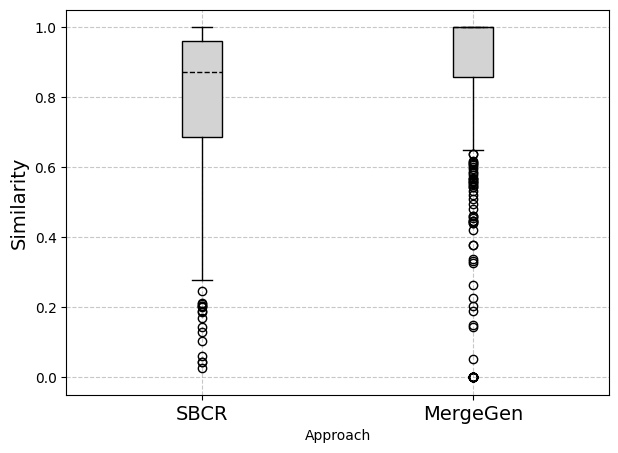

In [11]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ2_TypeScript_similarity_boxplot.png', dpi=300) 
plt.show()  

In [12]:
# Normality test
stat_shapiro_sbcr, p_shapiro_sbcr = stats.shapiro(df_results_clean['sim_sbcr'])
stat_shapiro_mergegen, p_shapiro_mergegen = stats.shapiro(df_results_clean['sim_mergegen'])

print(f"Shapiro-Wilk Test for SBCR: W={stat_shapiro_sbcr}, p={p_shapiro_sbcr}")
print(f"Shapiro-Wilk Test for MergeGen: W={stat_shapiro_mergegen}, p={p_shapiro_mergegen}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

Shapiro-Wilk Test for SBCR: W=0.8423575758934021, p=4.786828672591253e-22
Shapiro-Wilk Test for MergeGen: W=0.5824914574623108, p=4.4291517766190205e-33
Levene Test: W=6.044745811718202, p=0.0141143118725575


In [13]:
# Not normal and not homocedastic. We use non-parametric paired test Wilcoxon
pg.wilcoxon(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'], alternative='two-sided')

# https://pingouin-stats.org/build/html/index.html
# Interpretation: https://peterstatistics.com/Terms/Correlations/RankBiserialCorrelation.html

,W-val,alternative,p-val,RBC,CLES
Wilcoxon,23585.0,two-sided,6.946453e-19,-0.493319,0.29272


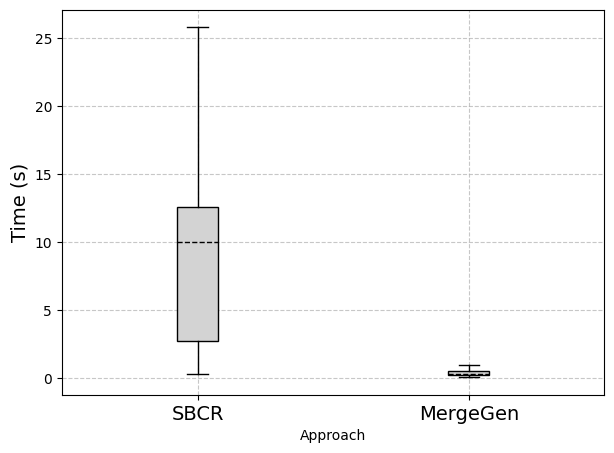

In [16]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['time_sbcr'], df_results_clean['time_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('RQ2_TypeScript_time_boxplot.png', dpi=300) 
plt.show()  